# Modelagem Matemática do Lançamento de um Foguete


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1) Modelo de Pressão Aerodinâmica $P(t)$

### Escolha da forma da função
A gente quer uam curva que:
- comece em zero no instante do lançamento ($P(0)=0$),
- cresça no início,
- atinja um pico (Max Q),
- depois caia.

Uma função simples que faz isso é:
$$
P(t) = A\,t\,e^{-k t}, \quad t\ge 0
$$
com $A>0$ e $k>0$.

Neste trabalho vamos usar:
- $A = 7.2$ (escala da pressão),
- $k = 0.04$ (taxa de decaimento),
- tempo em segundos.

In [2]:
A = 7.2
k = 0.04

def P(t):
    return A * t * np.exp(-k * t)

def dP(t):
    # Derivada: P'(t) = A*e^(-kt)*(1 - kt)
    return A * np.exp(-k * t) * (1 - k * t)

### Derivada e ponto crítico (Max Q)
No topo da curva a inclinação da tangente é zero, então:
$$
P'(t)=0 \Rightarrow 1-k t=0 \Rightarrow t^*=\frac{1}{k}
$$
Logo, com $k=0.04$:
$$
t^* = 25\ \text{s}
$$
Esse valor é fisicamente plausível: o pico ocorre cedo no voo, quando o foguete ainda cruza atmosfera densa.

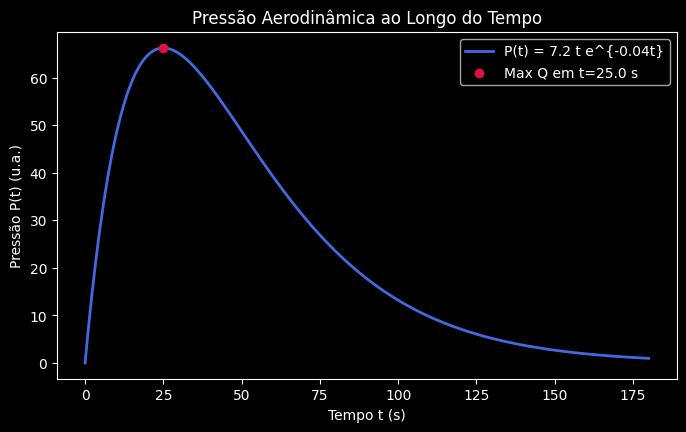

P(0) = 0.00
Max Q em t* = 25.00 s
P(t*) = 66.22
P'(t*) = 0.000000


In [3]:
t = np.linspace(0, 180, 500)
t_maxq = 1 / k
p_maxq = P(t_maxq)

plt.figure(figsize=(8, 4.5))
plt.plot(t, P(t), label='P(t) = 7.2 t e^{-0.04t}', color='royalblue', linewidth=2)
plt.scatter([t_maxq], [p_maxq], color='crimson', zorder=3, label=f'Max Q em t={t_maxq:.1f} s')
plt.title('Pressão Aerodinâmica ao Longo do Tempo')
plt.xlabel('Tempo t (s)')
plt.ylabel('Pressão P(t) (u.a.)')
plt.legend()
plt.show()

print(f'P(0) = {P(0):.2f}')
print(f'Max Q em t* = {t_maxq:.2f} s')
print(f'P(t*) = {p_maxq:.2f}')
print(f'P\'(t*) = {dP(t_maxq):.6f}')

## 2) Modelo de Risco em função da Temperatura $R(T)$

### Ideia física
- Em temperaturas baixas, risco maior (problema dos O-rings no Challenger).
- Com aumento de temperatura, o risco diminui.
- Mesmo com temperatura alta, o risco não deve ser exatamente zero (risco residual).

Uma função simples com assíntota horizontal é:
$$
R(T)=R_{min}+C\,e^{-\alpha (T-T_0)}
$$
com $R_{min}>0$, $C>0$, $\alpha>0$.

Vamos usar:
- $R_{min}=0.02$ (2% de risco residual),
- $C=0.60$,
- $\alpha=0.08$,
- $T_0=20^\circ C$.

In [4]:
R_min = 0.02
C = 0.60
alpha = 0.08
T0 = 20

def R(T):
    return R_min + C * np.exp(-alpha * (T - T0))

def dR(T):
    # Derivada: R'(T) = -alpha*C*e^{-alpha(T-T0)} < 0
    return -alpha * C * np.exp(-alpha * (T - T0))

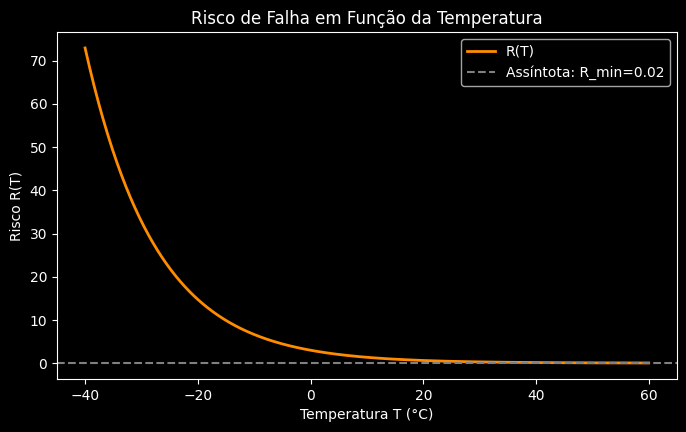

R(-20 °C) = 14.7395 | R'(-20 °C) = -1.1776
R(  0 °C) = 2.9918 | R'(  0 °C) = -0.2377
R( 20 °C) = 0.6200 | R'( 20 °C) = -0.0480
R( 40 °C) = 0.1411 | R'( 40 °C) = -0.0097


In [6]:
T = np.linspace(-40, 60, 500)

plt.figure(figsize=(8, 4.5))
plt.plot(T, R(T), color='darkorange', linewidth=2, label='R(T)')
plt.axhline(R_min, color='gray', linestyle='--', label=f'Assíntota: R_min={R_min:.2f}')
plt.title('Risco de Falha em Função da Temperatura')
plt.xlabel('Temperatura T (°C)')
plt.ylabel('Risco R(T)')
plt.legend()
plt.show()

temps = [-20, 0, 20, 40]
for temp in temps:
    print(f'R({temp:>3} °C) = {R(temp):.4f} | R\'({temp:>3} °C) = {dR(temp):.4f}')

## 3) Validação e Rigor Matemático

### Domínio e unidades
- Para pressão: $t\ge 0$ (tempo negativo não faz sentido no contexto do voo).
- Para temperatura operacional: pode variar bastante, mas usamos aqui um intervalo de estudo de $[-40,60]^\circ C$.

### Interpretação das derivadas
- $P'(t)$: taxa de variação da pressão no tempo.
  - $P'(t)>0$: pressão aumentando.
  - $P'(t)=0$: pico de pressão (Max Q).
  - $P'(t)<0$: pressão diminuindo.
- $R'(T)<0$: ao aumentar a temperatura, o risco diminui.

### Máximos e mínimos
- Máximo de $P(t)$ ocorre em $t^*=25\,s$ (consistente com fase inicial do voo).
- Mínimo teórico de $R(T)$ é a assíntota $R_{min}=0.02$, nunca zero.

Isso respeita o comportamento físico esperado: risco nunca desaparece totalmente.

## 4) Conclusão
Foram propostos dois modelos simples e coerentes com a física do problema:

1. $P(t)=7.2 t e^{-0.04t}$ representa bem a sequência de subida da pressão, pico (Max Q) e queda.
2. $R(T)=0.02+0.60e^{-0.08(T-20)}$ representa o aumento de risco no frio e a existência de risco residual no calor.

Mesmo sem usar dados reais de telemetria, os modelos passam no teste de realidade, têm interpretação de derivada, domínio definido e comportamento matemático adequado.